# Reconstructing Arctic sea-ice velocity with a neural network: an observing-system-design tutorial

*AI4InSync / OAISIS — KITP 2025*

**What we do in this notebook**

1. Load CMIP6 model output that has been *co-located* to the times and positions of real Ice-Tethered Profiler (ITP) tracks in the Arctic. These are our **synthetic observations**.
2. Train a small neural network to predict sea-ice velocity (`siu`, `siv`) from wind (`uas`, `vas`), ice concentration (`sic`), day-of-year and position — using only the synthetic observations.
3. Apply the trained network to **every grid cell** of the model (where the inputs are known everywhere) and compare the reconstructed velocity maps with the model's true velocity.
4. **Observing-system design (OSD):** retrain with a different subset of the synthetic observations and ask how the reconstruction skill changes. That is the question an observing-system designer asks: *where/when do extra observations help most?*

Data: `data/oaisis_tutorial_IPSL.nc` (ships with this repository; how it was made is in `preprocessing/README.md`).

## 0. Setup

Everything the notebook needs is in this repository: one NetCDF file in `data/` and the packages in `requirements.txt`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | xarray {xr.__version__} | tensorflow {tf.__version__}")

python 3.10.19 | numpy 1.23.5 | xarray 2024.7.0 | tensorflow 2.14.0


In [2]:
DATA = Path("data/oaisis_tutorial_IPSL.nc")
ds = xr.open_dataset(DATA)
ds

<xarray.Dataset> Size: 12MB
Dimensions:         (member: 31, sample: 11242, y: 65, x: 360, time: 10)
Coordinates:
  * member          (member) <U9 1kB 'r1i1p1f1' 'r2i1p1f1' ... 'r31i1p1f1'
    obs_lat         (sample) float64 90kB ...
    obs_lon         (sample) float64 90kB ...
    obs_time        (sample) datetime64[ns] 90kB ...
    map_lat         (y, x) float64 187kB ...
    map_lon         (y, x) float64 187kB ...
    map_time        (time) datetime64[ns] 80B ...
Dimensions without coordinates: sample, y, x, time
Data variables:
    obs_uas         (member, sample) float32 1MB ...
    obs_vas         (member, sample) float32 1MB ...
    obs_sic         (member, sample) float32 1MB ...
    obs_siu         (member, sample) float32 1MB ...
    obs_siv         (member, sample) float32 1MB ...
    map_uas         (y, x, time) float32 936kB ...
    map_vas         (y, x, time) float32 936kB ...
    map_sic         (y, x, time) float32 936kB ...
    map_siu         (y, x, time) float32 936kB ...
    map_siv         (y, x, time) float32 936kB ...
    map_grid_angle  (y, x) float32 94kB ...
Attributes:
    title:        OAISIS ML tutorial: synthetic Arctic sea-ice observations a...
    summary:      Two parts. (1) obs_*: daily output of 31 IPSL-CM6A-LR histo...
    source:       CMIP6 CMIP historical, IPSL-CM6A-LR, daily (SIday: siu, siv...
    references:   Boucher et al. 2020 (IPSL-CM6A-LR); Toole et al. 2011, Kris...
    conventions:  units and standard_name follow CF where a name exists
    processing:   scripts in preprocessing/ of https://github.com/lahoffman/m...
    history:      2026-10-19: built with preprocessing/05b_build_dataset_from...

## 1. Synthetic observations

### 1.1 About the data

**Ice-Tethered Profilers (ITPs)** drift with the sea ice and report their position daily, so their tracks give us a realistic *sampling pattern* of the Arctic (Toole et al., 2011; Krishfield et al., 2008; https://www.whoi.edu/itp).

We don't use the ITP measurements themselves. Instead we take daily output from CMIP6 historical simulations and pick, for every ITP position/day, the model value at the nearest grid cell and date. The result is a set of **synthetic observations** at the ITP locations where we know the truth everywhere else as well — exactly what is needed to test an observing system.

The dataset has two parts, both from the CMIP6 historical simulation of **IPSL-CM6A-LR**:

* `obs_*` — 31 ensemble members × 11 242 ITP samples (2004–2014): the synthetic observations. Dimensions `(member, sample)`, plus `obs_lat`, `obs_lon`, `obs_time` per sample.
* `map_*` — daily Arctic fields from member r1 on the model's native ocean grid, used as the truth for the reconstruction. Dimensions `(y, x, time)`.

Variables: `uas`, `vas` 10 m wind [m/s]; `sic` sea-ice concentration [%]; `siu`, `siv` sea-ice velocity [m/s]. All velocity components are **eastward / northward**. (CMIP6 stores ice velocity along the model grid's own axes, which on IPSL's tripolar grid are rotated by tens of degrees from east; the preprocessing rotated them, see `preprocessing/README.md`.) Every variable carries `long_name`, `units` and a `comment` — look at `ds` above.

In [3]:
MEMBERS = list(ds.member.values)                 # 'r1i1p1f1' ... 'r31i1p1f1'
lat_obs = ds.obs_lat.values
lon_obs = ds.obs_lon.values
doy_obs = ds.obs_time.dt.dayofyear.values

print("members:", len(MEMBERS), "| samples:", lat_obs.size,
      "| period:", str(ds.obs_time.min().values)[:10], "to", str(ds.obs_time.max().values)[:10],
      "| latitude %.1f-%.1f N" % (lat_obs.min(), lat_obs.max()))

members: 31 | samples: 11242 | period: 2004-08-20 to 2014-12-31 | latitude 71.2-89.9 N


### 1.2 A look at the synthetic observations

Left: where the ITPs were. Right: what the model says the ice was doing there (for one ensemble member).

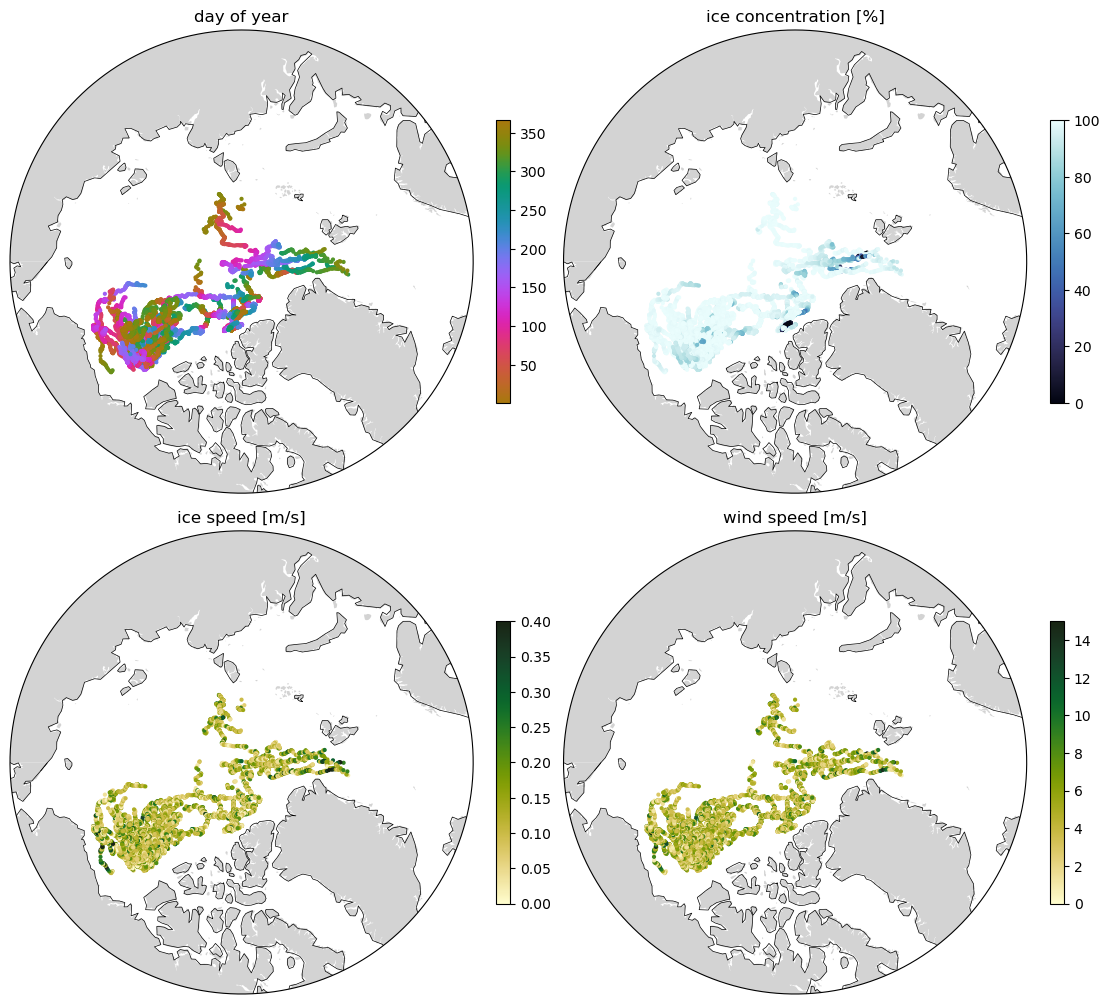

In [4]:
import matplotlib.path as mpath

def polar_axes(ax, title="", lat_min=65):
    '''North-polar map with a circular boundary. Limits are set in projected coordinates
    (set_extent with a full longitude range is unreliable across cartopy versions).'''
    x, y = ax.projection.transform_point(0, lat_min, ccrs.PlateCarree())
    r = np.hypot(x, y)
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    theta = np.linspace(0, 2 * np.pi, 200)
    ax.set_boundary(mpath.Path(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5), transform=ax.transAxes)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
    ax.coastlines(resolution="110m", linewidth=0.5)
    ax.set_title(title)

member = "r1i1p1f1"
m = ds.sel(member=member)
speed_ice = np.hypot(m.obs_siu, m.obs_siv)
speed_wind = np.hypot(m.obs_uas, m.obs_vas)

fig, axs = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
panels = [("day of year", doy_obs, cmocean.cm.phase, {}),
          ("ice concentration [%]", m.obs_sic, cmocean.cm.ice, {"vmin": 0, "vmax": 100}),
          ("ice speed [m/s]", speed_ice, cmocean.cm.speed, {"vmin": 0, "vmax": 0.4}),
          ("wind speed [m/s]", speed_wind, cmocean.cm.speed, {"vmin": 0, "vmax": 15})]
for ax, (title, c, cmap, kw) in zip(axs.flat, panels):
    polar_axes(ax, title)
    sc = ax.scatter(lon_obs, lat_obs, c=c, s=4, cmap=cmap, transform=ccrs.PlateCarree(), **kw)
    plt.colorbar(sc, ax=ax, shrink=0.6)

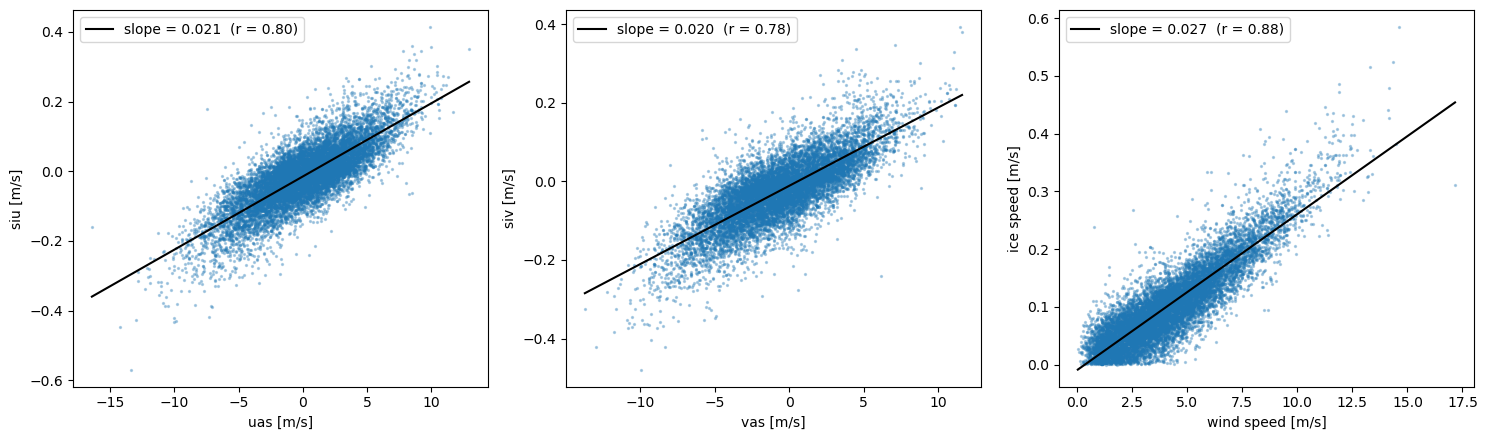

In [5]:
# relationships between inputs and targets (one member)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y, xl, yl) in zip(axs, [(m.obs_uas, m.obs_siu, "uas [m/s]", "siu [m/s]"),
                                    (m.obs_vas, m.obs_siv, "vas [m/s]", "siv [m/s]"),
                                    (speed_wind, speed_ice, "wind speed [m/s]", "ice speed [m/s]")]):
    ax.scatter(x, y, s=2, alpha=0.3)
    p = np.polyfit(x, y, 1)
    xx = np.linspace(float(x.min()), float(x.max()), 2)
    ax.plot(xx, np.polyval(p, xx), "k-", label=f"slope = {p[0]:.3f}  (r = {np.corrcoef(x, y)[0,1]:.2f})")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend()
plt.tight_layout()

Ice drifts at roughly 2 % of the wind speed (the classic Nansen rule), and the correlation is high — a good sign that wind is a strong predictor. The scatter around the line is what ice concentration, season and location have to explain.

### 1.3 Building the machine-learning dataset

**Inputs (features):** `uas`, `vas`, `sic`, `doy`, `lat`, `cos(lon)`, `sin(lon)`
**Targets:** `siu`, `siv`

Longitude goes in as its cosine and sine rather than as a number: `lon/180` jumps from +1 to −1 at the dateline, and a network fed that will happily produce a jump in ice velocity across 180° W. Day of year has the same wrap-around (31 Dec → 1 Jan); with only a decade of ITPs it matters less, but try `cos`/`sin` there too.

Everything is written as a function of a dataset so that we apply *exactly the same* feature construction and scaling to the ITP samples (training) and to the full maps (reconstruction). Mixing these up is the easiest way to get a silently wrong reconstruction.

In [6]:
FEATURES = ["uas", "vas", "sic", "doy", "lat", "cos_lon", "sin_lon"]
TARGETS = ["siu", "siv"]

def make_table(uas, vas, sic, doy, lat, lon, siu=None, siv=None):
    '''Stack broadcastable arrays into X (n, 7) and Y (n, 2). Returns Y=None if targets are missing.'''
    arrs = np.broadcast_arrays(uas, vas, sic, doy, lat, np.cos(np.radians(lon)), np.sin(np.radians(lon)))
    X = np.stack([a.ravel() for a in arrs], axis=1).astype("float32")
    Y = None
    if siu is not None:
        siu, siv = np.broadcast_arrays(siu, siv)
        Y = np.stack([siu.ravel(), siv.ravel()], axis=1).astype("float32")
    return X, Y

def obs_table(members, sample_mask=None):
    '''Feature/target table for the given ensemble members, optionally for a subset of the ITP samples.'''
    sel = slice(None) if sample_mask is None else sample_mask
    g = lambda v: ds["obs_" + v].sel(member=members).values[:, sel]      # (n_members, n_samples)
    return make_table(g("uas"), g("vas"), g("sic"), doy_obs[None, sel], lat_obs[None, sel], lon_obs[None, sel], g("siu"), g("siv"))

#### Train / validation / test split

We split by **ensemble member**, not by random sample: consecutive days along an ITP track are strongly correlated, so a random split would leak information from train to test and make the model look better than it is. Member r1 provides the reconstruction maps in section 3, so it is kept out of training.

In [7]:
SPLIT = {"train": MEMBERS[1:21], "val": MEMBERS[21:26], "test": [MEMBERS[0]] + MEMBERS[26:31]}

X_tr, Y_tr = obs_table(SPLIT["train"])
X_va, Y_va = obs_table(SPLIT["val"])
X_te, Y_te = obs_table(SPLIT["test"])
for k, X in zip(SPLIT, (X_tr, X_va, X_te)):
    print(f"{k:5s}: {len(SPLIT[k]):2d} members ({SPLIT[k][0]} ... {SPLIT[k][-1]})  ->  {X.shape[0]:7d} samples")

train: 20 members (r2i1p1f1 ... r21i1p1f1)  ->   224840 samples
val  :  5 members (r22i1p1f1 ... r26i1p1f1)  ->    56210 samples
test :  6 members (r1i1p1f1 ... r31i1p1f1)  ->    67452 samples


#### Feature scaling

Inputs with very different ranges (wind ±20 m/s, concentration 0–100 %, latitude 70–90°) would otherwise be weighted unevenly. We standardize the physical variables with the **training** mean and standard deviation (using anything else would be data leakage), and map the geometric inputs to fixed ranges: `doy/365`, `lat/90`; `cos_lon`/`sin_lon` are already in [−1, 1]. The targets are standardized too, so the loss is in units of "standard deviations of ice velocity".

In [8]:
class Scaler:
    '''Standardize features/targets with training statistics. Fixed scaling for doy, lat, lon.'''
    fixed = {"doy": 365.0, "lat": 90.0, "cos_lon": 1.0, "sin_lon": 1.0}

    def fit(self, X, Y):
        self.x_mean, self.x_std = X.mean(0), X.std(0)
        self.y_mean, self.y_std = Y.mean(0), Y.std(0)
        for name, s in self.fixed.items():          # geometric inputs: divide by a constant
            i = FEATURES.index(name)
            self.x_mean[i], self.x_std[i] = 0.0, s
        return self

    def x(self, X):  return (X - self.x_mean) / self.x_std
    def y(self, Y):  return (Y - self.y_mean) / self.y_std
    def y_inv(self, Z): return Z * self.y_std + self.y_mean

scaler = Scaler().fit(X_tr, Y_tr)
x_tr, y_tr = scaler.x(X_tr), scaler.y(Y_tr)
x_va, y_va = scaler.x(X_va), scaler.y(Y_va)
x_te, y_te = scaler.x(X_te), scaler.y(Y_te)

print("scaled feature ranges (train):")
for i, f in enumerate(FEATURES):
    print(f"  {f:7s} [{x_tr[:, i].min():6.2f}, {x_tr[:, i].max():6.2f}]")

scaled feature ranges (train):
  uas     [ -4.38,   4.77]
  vas     [ -4.64,   4.65]
  sic     [ -7.87,   0.36]
  doy     [  0.00,   1.00]
  lat     [  0.79,   1.00]
  cos_lon [ -1.00,   1.00]
  sin_lon [ -1.00,   1.00]


## 2. Neural network

### 2.1 Metrics

* **Skill** $= 1 - \mathrm{RMSE}/\sigma_{\rm true}$: 1 is perfect, 0 means "no better than predicting the mean", negative means worse than the mean. It penalises bias and wrong amplitude.
* **Correlation** $r$: pattern agreement only — a prediction can have $r \approx 1$ and still be biased or too weak. Always look at both.

We compute them *per velocity component* so that the difference between `siu` and `siv` doesn't masquerade as skill.

In [9]:
def skill(y_true, y_pred, axis=0):
    rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
    return 1.0 - rmse / np.nanstd(y_true, axis=axis)

def corr(y_true, y_pred, axis=0):
    a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
    b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
    return np.nansum(a * b, axis=axis) / np.sqrt(np.nansum(a * a, axis=axis) * np.nansum(b * b, axis=axis))

def report(y_true, y_pred, label=""):
    s, c = skill(y_true, y_pred), corr(y_true, y_pred)
    print(f"{label:12s} skill  siu={s[0]:.3f}  siv={s[1]:.3f} | corr  siu={c[0]:.3f}  siv={c[1]:.3f}")
    return s, c

# Keras versions of the same quantities, used during training
def nrmse_loss(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true))) / (tf.math.reduce_std(y_true) + 1e-7)

def corr_metric(y_true, y_pred):
    a = y_true - tf.reduce_mean(y_true); b = y_pred - tf.reduce_mean(y_pred)
    return tf.reduce_sum(a * b) / (tf.sqrt(tf.reduce_sum(a * a) * tf.reduce_sum(b * b)) + 1e-7)

### 2.2 Hyperparameters

Things you can play with. Try: more units/layers, a smaller learning rate with more epochs, dropout vs. L2 regularization, or a plain `'mse'` loss.

In [10]:
HP = dict(
    n_units=16,        # neurons per hidden layer
    n_layers=2,        # hidden layers
    dropout=0.0,       # dropout rate (0 = off)
    l2=1e-3,           # L2 weight penalty
    lr=1e-2,           # learning rate
    epochs=15,
    batch_size=256,
    activation="relu",
)

In [11]:
def build_model(n_in, n_out, n_units, n_layers, dropout, l2, lr, activation, **_):
    model = keras.Sequential([layers.Input(shape=(n_in,))])
    for _ in range(n_layers):
        model.add(layers.Dense(n_units, activation=activation, kernel_regularizer=keras.regularizers.l2(l2)))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_out))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=nrmse_loss, metrics=[corr_metric])
    return model

def train_model(x_tr, y_tr, x_va, y_va, hp=HP, verbose=0, seed=0):
    keras.utils.set_random_seed(seed)
    model = build_model(x_tr.shape[1], y_tr.shape[1], **hp)
    hist = model.fit(x_tr, y_tr, validation_data=(x_va, y_va), epochs=hp["epochs"],
                     batch_size=hp["batch_size"], shuffle=True, verbose=verbose)
    return model, hist.history

def plot_history(h):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, k, lab in zip(axs, ["loss", "corr_metric"], ["loss (NRMSE)", "correlation"]):
        ax.plot(h[k], label="train"); ax.plot(h["val_" + k], label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(lab); ax.legend()
    plt.tight_layout()

### 2.3 Train

Epoch 1/15
879/879 [==============================] - 1s 497us/step - loss: 0.3425 - corr_metric: 0.9418 - val_loss: 0.3424 - val_corr_metric: 0.9510
Epoch 2/15
879/879 [==============================] - 0s 403us/step - loss: 0.3199 - corr_metric: 0.9521 - val_loss: 0.3334 - val_corr_metric: 0.9533
Epoch 3/15
879/879 [==============================] - 0s 403us/step - loss: 0.3170 - corr_metric: 0.9525 - val_loss: 0.3265 - val_corr_metric: 0.9532
Epoch 4/15
879/879 [==============================] - 0s 402us/step - loss: 0.3151 - corr_metric: 0.9529 - val_loss: 0.3282 - val_corr_metric: 0.9537
Epoch 5/15
879/879 [==============================] - 0s 397us/step - loss: 0.3147 - corr_metric: 0.9530 - val_loss: 0.3270 - val_corr_metric: 0.9534
Epoch 6/15
879/879 [==============================] - 0s 395us/step - loss: 0.3135 - corr_metric: 0.9532 - val_loss: 0.3364 - val_corr_metric: 0.9510
Epoch 7/15
879/879 [==============================] - 0s 407us/step - loss: 0.3125 - corr_metric: 0.

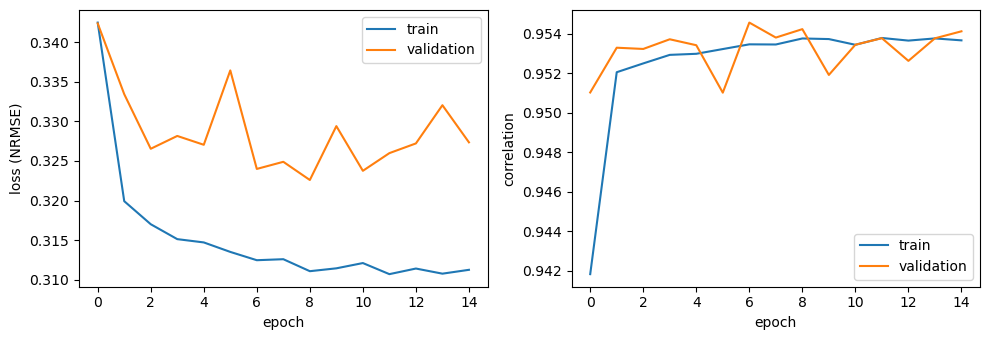

In [12]:
model, history = train_model(x_tr, y_tr, x_va, y_va, verbose=1)
model.summary()
plot_history(history)

### 2.4 Evaluate on the held-out test members

The model has never seen these ensemble members. Note that we evaluate in *physical* units (m/s) after undoing the scaling.

test         skill  siu=0.687  siv=0.699 | corr  siu=0.952  siv=0.954


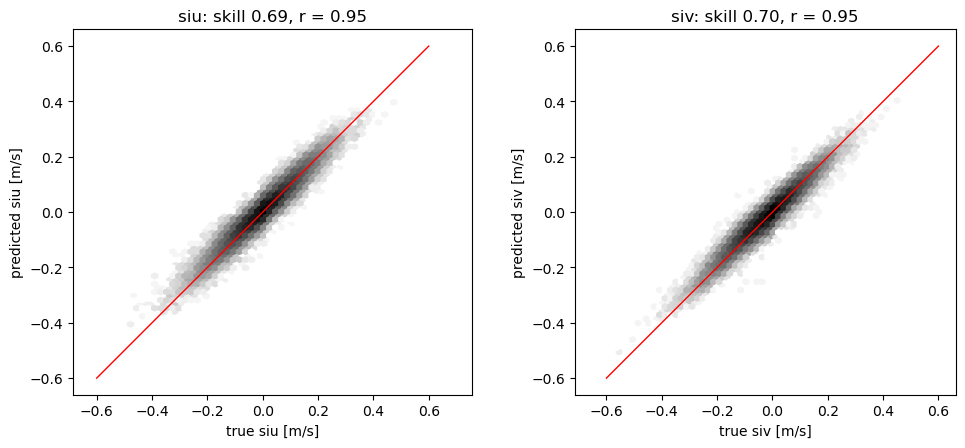

In [13]:
Y_pred_te = scaler.y_inv(model.predict(x_te, verbose=0))
s_te, c_te = report(Y_te, Y_pred_te, "test")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, k, name in zip(axs, range(2), TARGETS):
    ax.hexbin(Y_te[:, k], Y_pred_te[:, k], gridsize=60, bins="log", cmap="Greys")
    ax.plot([-0.6, 0.6], [-0.6, 0.6], "r-", lw=1)
    ax.set_xlabel(f"true {name} [m/s]"); ax.set_ylabel(f"predicted {name} [m/s]")
    ax.set_title(f"{name}: skill {s_te[k]:.2f}, r = {c_te[k]:.2f}"); ax.set_aspect("equal")
plt.tight_layout()

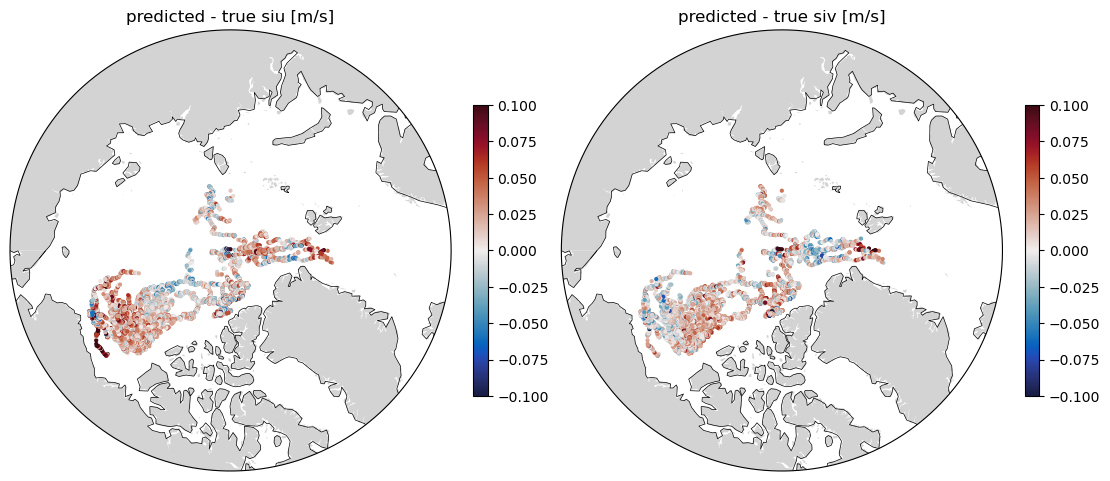

In [14]:
# where along the ITP tracks is the error largest? (one test member)
err = (Y_pred_te - Y_te).reshape(len(SPLIT["test"]), -1, 2)[0]
fig, axs = plt.subplots(1, 2, figsize=(11, 5), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
for ax, k, name in zip(axs, range(2), TARGETS):
    polar_axes(ax, f"predicted - true {name} [m/s]")
    sc = ax.scatter(lon_obs, lat_obs, c=err[:, k], s=4, cmap=cmocean.cm.balance, vmin=-0.1, vmax=0.1, transform=ccrs.PlateCarree())
    plt.colorbar(sc, ax=ax, shrink=0.6)

## 3. Reconstruction: from ITP tracks to the whole Arctic

The inputs (wind, concentration, date, position) are known at every grid cell of the model. We feed them through the network trained on the ITP samples and compare the result with the model's own ice velocity — which the network has never seen outside the ITP tracks.

The `map_*` variables hold IPSL-CM6A-LR member r1 on its native ocean grid (`y` × `x` × `time`), north of 55 °N, NaN over land. Wind has already been put on the ice grid.

In [15]:
lat_map, lon_map = ds.map_lat.values, ds.map_lon.values
doy_map = ds.map_time.dt.dayofyear.values
sic_map, uas_map, vas_map, siu_map, siv_map = (ds["map_" + v].values for v in ("sic", "uas", "vas", "siu", "siv"))
ny, nx, nt = siu_map.shape
print(f"grid {ny} x {nx}, {nt} days: {str(ds.map_time[0].values)[:10]} to {str(ds.map_time[-1].values)[:10]}")

# ocean cells with ice: this is where a reconstruction is meaningful
ice_mask = np.isfinite(siu_map).all(axis=2) & (np.nanmean(sic_map, axis=2) > 15)
print(f"ice-covered ocean cells: {ice_mask.sum()} of {ny*nx}")

grid 65 x 360, 10 days: 2000-11-25 to 2000-12-04
ice-covered ocean cells: 4009 of 23400


/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/46270535.py:8: RuntimeWarning: Mean of empty slice
  ice_mask = np.isfinite(siu_map).all(axis=2) & (np.nanmean(sic_map, axis=2) > 15)


### 3.1 Plotting on a curvilinear grid

IPSL-CM6A-LR uses the NEMO tripolar ORCA1 grid. If you hand `pcolormesh` longitudes with `transform=PlateCarree()`, the cells that straddle the dateline (one per grid row) are drawn as long streaks across the map. Projecting the cell coordinates to the map's x/y *first* and drawing in those coordinates avoids the problem: in a polar stereographic plane there is no dateline. The last grid row is the "north fold" of the tripolar grid, where the grid meets its own mirror image; appending that mirror closes the gap.

Text(0.5, 0.98, 'IPSL-CM6A-LR r1, 2000-11-25')

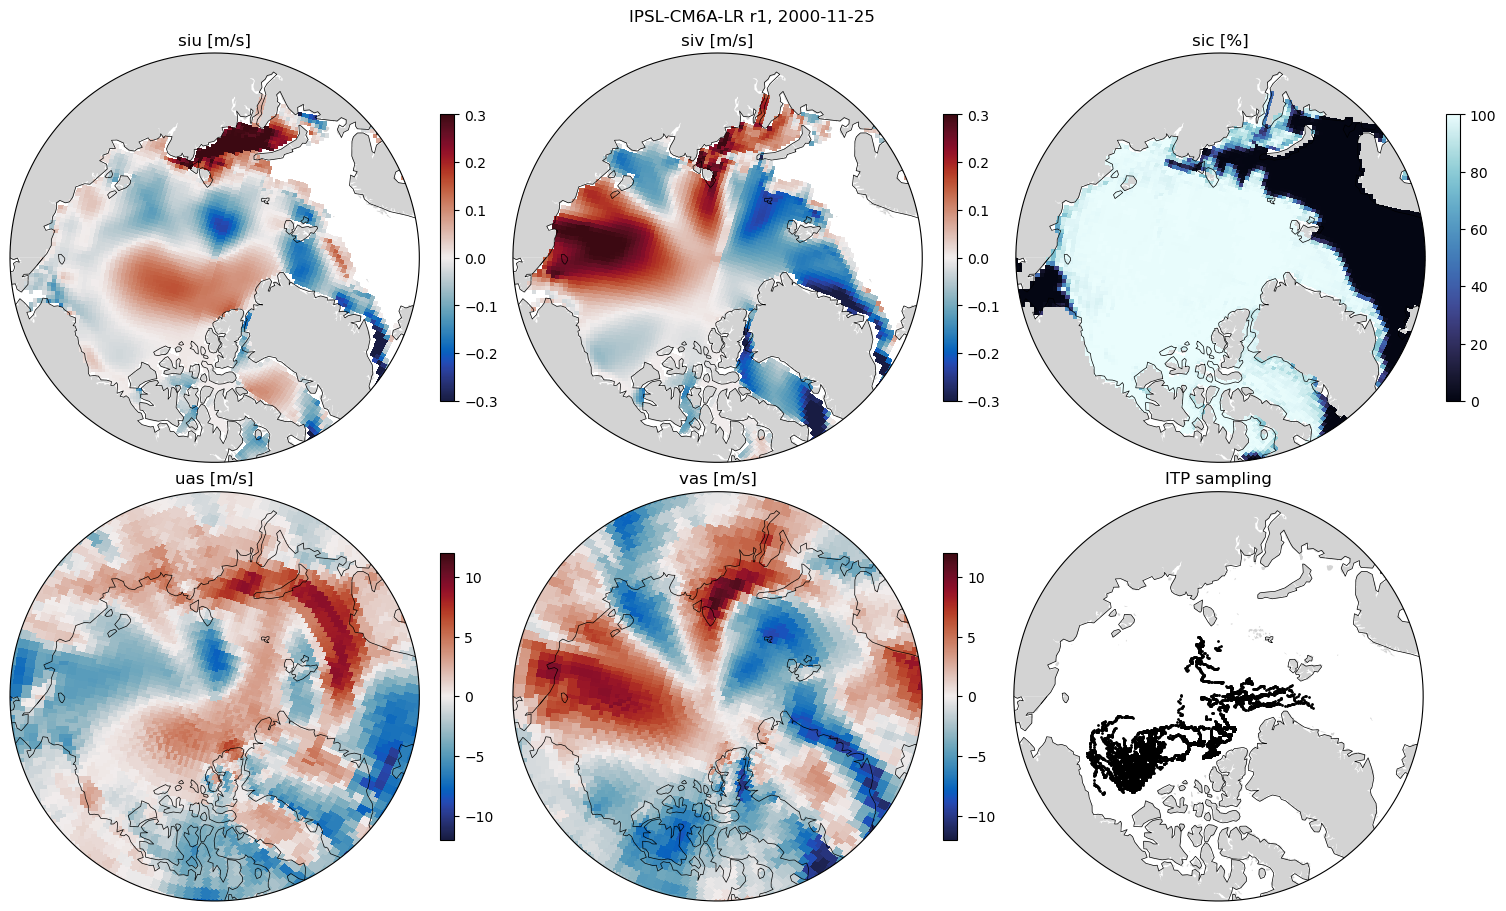

In [16]:
def polar_pcolormesh(ax, lon2d, lat2d, field, fold=True, **kw):
    '''pcolormesh on a curvilinear lat/lon grid, drawn in the map projection's own coordinates (no dateline streaks).
    fold=True appends the mirror image of the last row (ORCA north fold) so there is no gap along the fold line.'''
    if fold:
        perm = (lon2d.shape[1] - 2 - np.arange(lon2d.shape[1])) % lon2d.shape[1]   # cell j <-> cell (n-2-j) across the fold
        lon2d, lat2d, field = (np.vstack([a, a[-1:, perm]]) for a in (lon2d, lat2d, field))
    xyz = ax.projection.transform_points(ccrs.PlateCarree(), lon2d, lat2d)
    return ax.pcolormesh(xyz[..., 0], xyz[..., 1], np.ma.masked_invalid(field), shading="auto", **kw)

t = 0
fig, axs = plt.subplots(2, 3, figsize=(15, 9), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
fields = [("siu [m/s]", siu_map[:, :, t], cmocean.cm.balance, dict(vmin=-0.3, vmax=0.3)),
          ("siv [m/s]", siv_map[:, :, t], cmocean.cm.balance, dict(vmin=-0.3, vmax=0.3)),
          ("sic [%]", sic_map[:, :, t], cmocean.cm.ice, dict(vmin=0, vmax=100)),
          ("uas [m/s]", uas_map[:, :, t], cmocean.cm.balance, dict(vmin=-12, vmax=12)),
          ("vas [m/s]", vas_map[:, :, t], cmocean.cm.balance, dict(vmin=-12, vmax=12)),
          ("ITP sampling", None, None, {})]
for ax, (title, f, cmap, kw) in zip(axs.flat, fields):
    polar_axes(ax, title)
    if f is None:
        ax.scatter(lon_obs, lat_obs, s=1, c="k", transform=ccrs.PlateCarree())
    else:
        pm = polar_pcolormesh(ax, lon_map, lat_map, f, cmap=cmap, **kw)
        plt.colorbar(pm, ax=ax, shrink=0.7)
plt.suptitle(f"IPSL-CM6A-LR r1, {str(ds.map_time[t].values)[:10]}")

### 3.2 Reconstruct

Same `make_table` → same `scaler` → same model. The only new thing is reshaping the flat prediction back to `(ny, nx, nt, 2)`.

In [17]:
X_map, Y_map = make_table(uas_map, vas_map, sic_map, doy_map[None, None, :], lat_map[:, :, None], lon_map[:, :, None], siu_map, siv_map)
ok = np.isfinite(X_map).all(axis=1)              # land cells have NaN inputs

def reconstruct(model, X_map):
    pred = np.full((X_map.shape[0], 2), np.nan, dtype="float32")
    pred[ok] = scaler.y_inv(model.predict(scaler.x(X_map[ok]), verbose=0))
    return pred.reshape(ny, nx, nt, 2)

Y_true_map = Y_map.reshape(ny, nx, nt, 2)
Y_rec = reconstruct(model, X_map)

### 3.3 Skill of the reconstruction

Two views:

* **Pooled** over all ice-covered cells and days: one number per component, directly comparable to the test score in section 2.
* **Per grid cell** over the `nt` days: a map of where the reconstruction works. With only a few days per cell, $\sigma_{\rm true}$ is small and the per-cell skill is noisy and sensitive to any local bias, so treat the map as qualitative; cells with no ice or no variability are masked.

pooled       skill  siu=0.497  siv=0.600 | corr  siu=0.870  siv=0.917


/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:2: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
/Users/lahoffma/miniforge3/envs/slowdown-seaice/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:3: RuntimeWarning: divide by zero encountered in divide
  return 1.0 - rmse / np.nanstd(y_true, axis=axis)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:6: RuntimeWarning: Mean of empty slice
  a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:7: RuntimeWarning: Mean of empty slice
  b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipyke

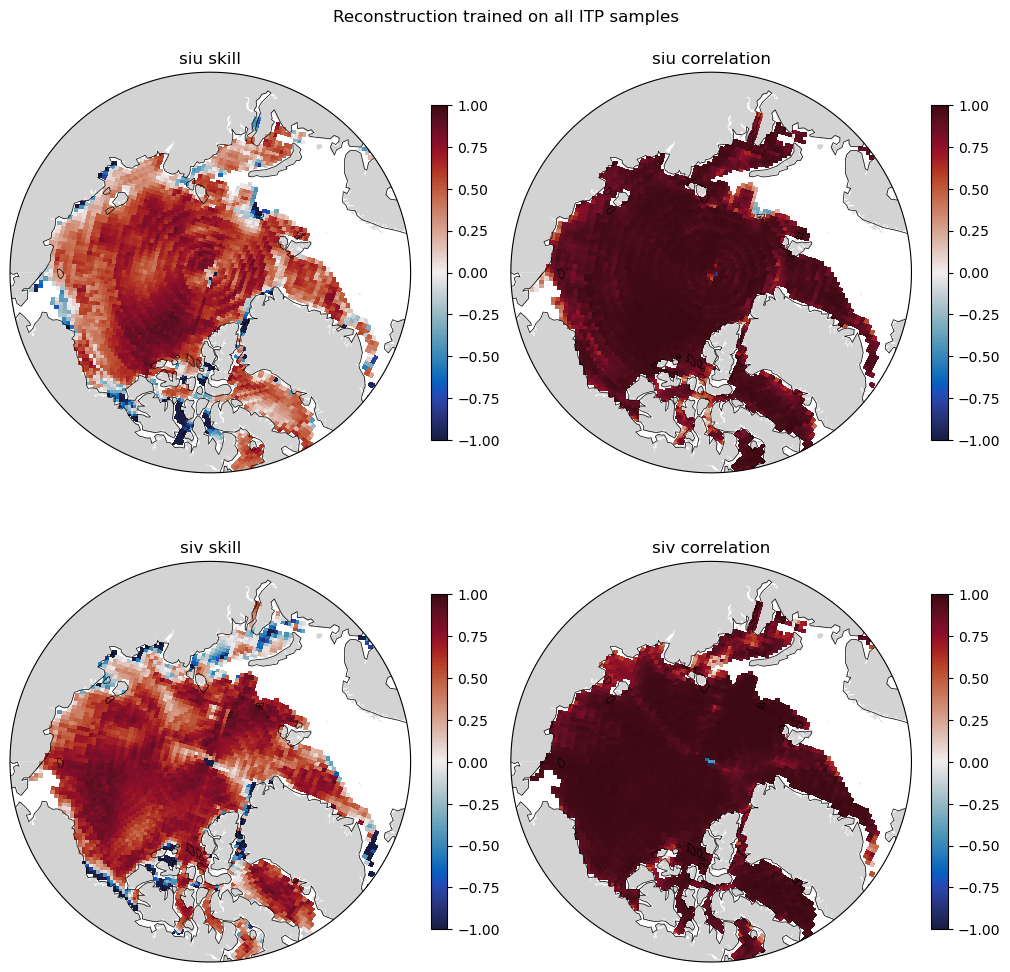

In [18]:
def pooled_scores(Y_true, Y_rec, mask=ice_mask):
    yt, yp = Y_true[mask].reshape(-1, 2), Y_rec[mask].reshape(-1, 2)
    return report(yt, yp, "pooled")

def cell_scores(Y_true, Y_rec, mask=ice_mask, min_std=0.01):
    '''Per-cell skill and correlation (ny, nx, 2), computed over time, masked where variance is tiny.'''
    s = skill(Y_true, Y_rec, axis=2); c = corr(Y_true, Y_rec, axis=2)
    low = (np.nanstd(Y_true, axis=2) < min_std) | ~mask[:, :, None]
    s[low] = np.nan; c[low] = np.nan
    return s, c

def plot_cell_scores(s, c, title=""):
    fig, axs = plt.subplots(2, 2, figsize=(10, 10), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
    for k, name in enumerate(TARGETS):
        for j, (f, lab) in enumerate([(s[:, :, k], "skill"), (c[:, :, k], "correlation")]):
            polar_axes(axs[k, j], f"{name} {lab}")
            pm = polar_pcolormesh(axs[k, j], lon_map, lat_map, f, cmap=cmocean.cm.balance, vmin=-1, vmax=1)
            plt.colorbar(pm, ax=axs[k, j], shrink=0.7)
    plt.suptitle(title)

pooled_scores(Y_true_map, Y_rec)
s_full, c_full = cell_scores(Y_true_map, Y_rec)
plot_cell_scores(s_full, c_full, "Reconstruction trained on all ITP samples")

The reconstruction scores well below the test score of section 2 — and that is the point of the exercise, not a bug. The ITPs live in thick, slow pack ice (median concentration ≈ 95 %, ice speed σ ≈ 0.09 m/s); the maps also contain the marginal ice zone and early-winter coastal ice (σ ≈ 0.16 m/s, Fram Strait, Barents and Bering Seas, Baffin Bay) that no ITP has ever sampled. The network has to extrapolate there. Look at where the error map below is large: that is where new observations would be most valuable.

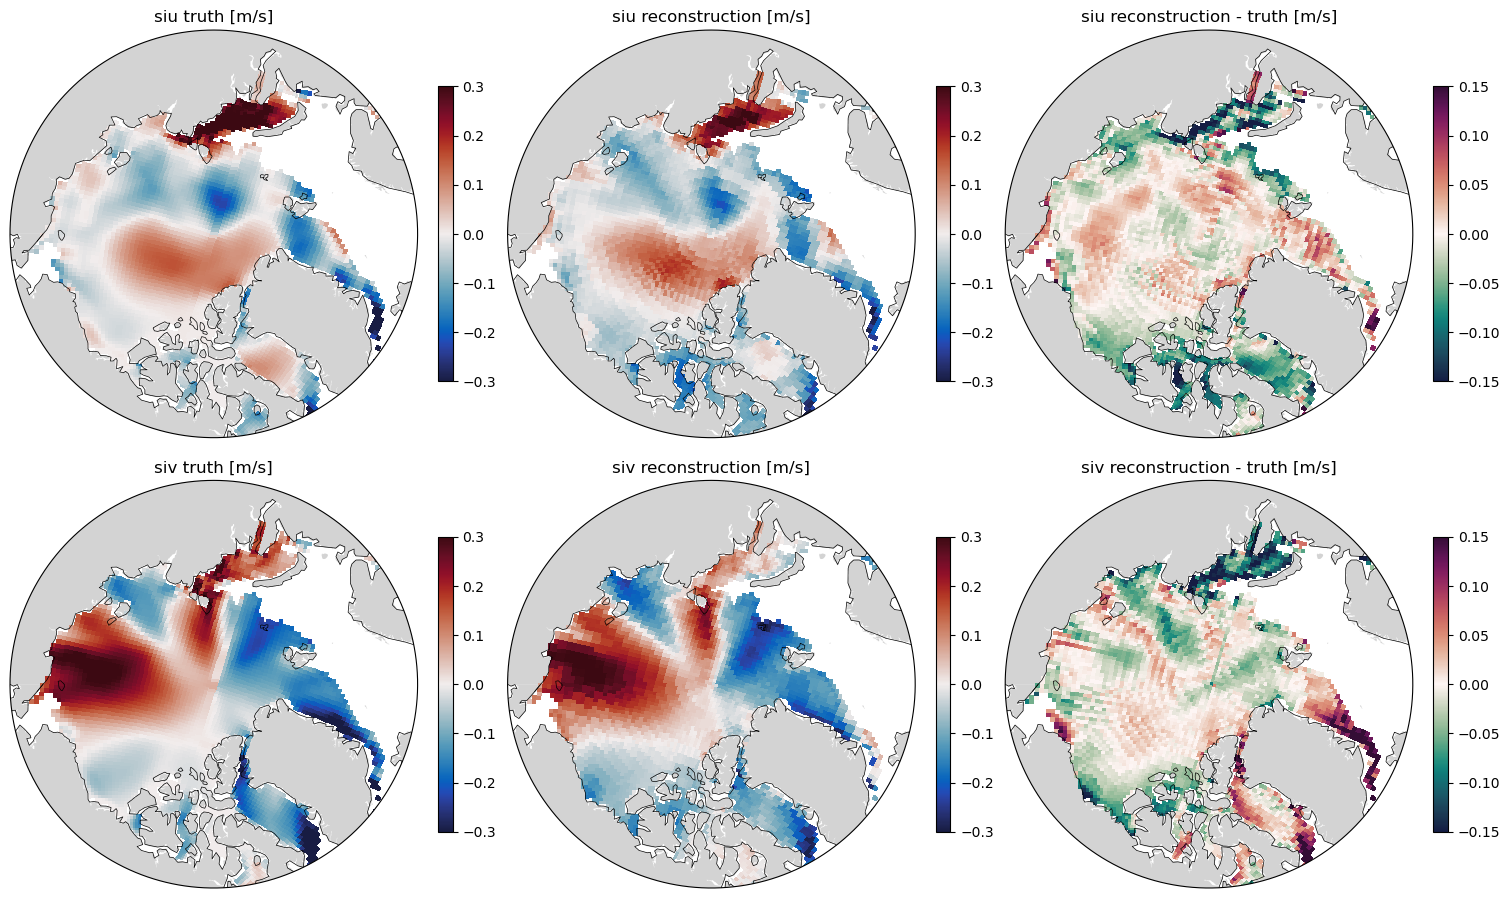

In [19]:
# the reconstruction itself vs. truth, one day
t = 0
fig, axs = plt.subplots(2, 3, figsize=(15, 9), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
for k, name in enumerate(TARGETS):
    for j, (f, lab, cmap, kw) in enumerate([(Y_true_map[:, :, t, k], "truth", cmocean.cm.balance, dict(vmin=-0.3, vmax=0.3)),
                                            (Y_rec[:, :, t, k], "reconstruction", cmocean.cm.balance, dict(vmin=-0.3, vmax=0.3)),
                                            (Y_rec[:, :, t, k] - Y_true_map[:, :, t, k], "reconstruction - truth", cmocean.cm.curl, dict(vmin=-0.15, vmax=0.15))]):
        polar_axes(axs[k, j], f"{name} {lab} [m/s]")
        pm = polar_pcolormesh(axs[k, j], lon_map, lat_map, np.where(ice_mask, f, np.nan), cmap=cmap, **kw)
        plt.colorbar(pm, ax=axs[k, j], shrink=0.7)

## 4. Observing-system design: what if we had different observations?

Everything above is wrapped into one function: give it a boolean mask over the ITP samples (*which synthetic observations do we get to use?*), it retrains the network and returns the reconstruction scores. Comparing scenarios tells us where additional (or fewer) observations change the reconstruction — the core OSD question.

Three example scenarios:

* `random20` — a random 20 % of the ITP samples (fewer observations, same coverage)
* `early20` — the first 20 % in time, i.e. only the 2004–2008 ITPs (fewer *and* different coverage)
* `no_beaufort` — drop everything in the Beaufort Sea (120–180 °W), to see how far skill transfers from unobserved regions

In [20]:
def run_scenario(sample_mask, name, hp=HP, seed=0):
    '''Retrain on a subset of ITP samples and score the Arctic reconstruction.'''
    tabs = {split: obs_table(mem, sample_mask) for split, mem in SPLIT.items()}
    sc = Scaler().fit(*tabs["train"])
    mdl, _ = train_model(sc.x(tabs["train"][0]), sc.y(tabs["train"][1]), sc.x(tabs["val"][0]), sc.y(tabs["val"][1]), hp=hp, seed=seed)
    pred = np.full((X_map.shape[0], 2), np.nan, dtype="float32")
    pred[ok] = sc.y_inv(mdl.predict(sc.x(X_map[ok]), verbose=0))
    Y_rec_s = pred.reshape(ny, nx, nt, 2)
    print(f"[{name}] {sample_mask.sum()} of {sample_mask.size} ITP samples")
    pooled_scores(Y_true_map, Y_rec_s)
    s, c = cell_scores(Y_true_map, Y_rec_s)
    return dict(name=name, model=mdl, Y_rec=Y_rec_s, skill=s, corr=c, mask=sample_mask)

rng = np.random.default_rng(0)
n = lat_obs.size
scenarios = {
    "all":         np.ones(n, bool),
    "random20":    rng.random(n) < 0.2,
    "early20":     np.arange(n) < n // 5,
    "no_beaufort": ~((lon_obs > -180) & (lon_obs < -120)),
}

In [21]:
results = {name: run_scenario(mask, name) for name, mask in scenarios.items()}

/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:2: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
/Users/lahoffma/miniforge3/envs/slowdown-seaice/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:3: RuntimeWarning: divide by zero encountered in divide
  return 1.0 - rmse / np.nanstd(y_true, axis=axis)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:6: RuntimeWarning: Mean of empty slice
  a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:7: RuntimeWarning: Mean of empty slice
  b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipyke

[all] 11242 of 11242 ITP samples
pooled       skill  siu=0.497  siv=0.600 | corr  siu=0.870  siv=0.917


/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:2: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
/Users/lahoffma/miniforge3/envs/slowdown-seaice/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:3: RuntimeWarning: divide by zero encountered in divide
  return 1.0 - rmse / np.nanstd(y_true, axis=axis)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:6: RuntimeWarning: Mean of empty slice
  a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:7: RuntimeWarning: Mean of empty slice
  b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipyke

[random20] 2290 of 11242 ITP samples
pooled       skill  siu=0.484  siv=0.581 | corr  siu=0.886  siv=0.912


/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:2: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
/Users/lahoffma/miniforge3/envs/slowdown-seaice/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:3: RuntimeWarning: divide by zero encountered in divide
  return 1.0 - rmse / np.nanstd(y_true, axis=axis)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:6: RuntimeWarning: Mean of empty slice
  a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:7: RuntimeWarning: Mean of empty slice
  b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipyke

[early20] 2248 of 11242 ITP samples
pooled       skill  siu=0.441  siv=0.591 | corr  siu=0.831  siv=0.916
[no_beaufort] 3799 of 11242 ITP samples
pooled       skill  siu=0.537  siv=0.603 | corr  siu=0.888  siv=0.919


/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:2: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((y_pred - y_true) ** 2, axis=axis))
/Users/lahoffma/miniforge3/envs/slowdown-seaice/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:3: RuntimeWarning: divide by zero encountered in divide
  return 1.0 - rmse / np.nanstd(y_true, axis=axis)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:6: RuntimeWarning: Mean of empty slice
  a = y_true - np.nanmean(y_true, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/4227104647.py:7: RuntimeWarning: Mean of empty slice
  b = y_pred - np.nanmean(y_pred, axis=axis, keepdims=True)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipyke

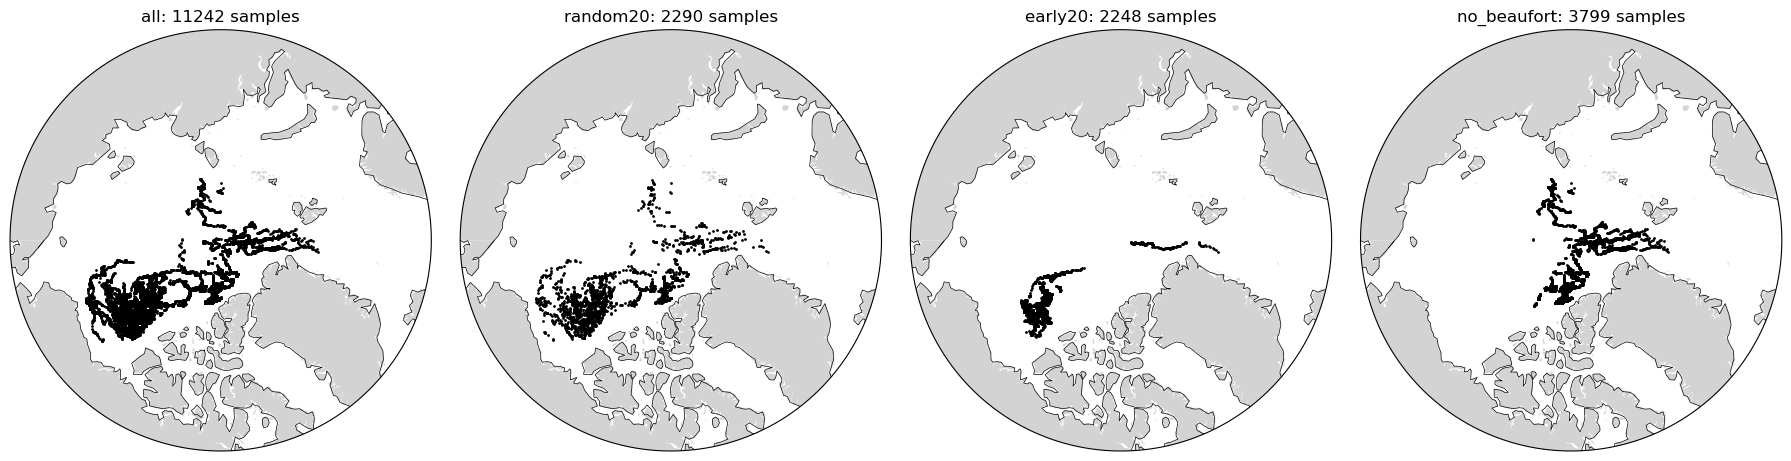

In [22]:
# sampling patterns of the scenarios
fig, axs = plt.subplots(1, len(scenarios), figsize=(4.5 * len(scenarios), 4.5), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
for ax, (name, m) in zip(axs, scenarios.items()):
    polar_axes(ax, f"{name}: {m.sum()} samples")
    ax.scatter(lon_obs[m], lat_obs[m], s=1, c="k", transform=ccrs.PlateCarree())

### 4.1 Where do the observations matter?

Skill of the full-coverage reconstruction *minus* skill of each scenario. Red: the observations that were removed were helping there. Blue: removing them made no difference (or helped — which with a small network and noisy per-cell scores can happen; retrain with a few seeds before reading too much into it).

Per-cell skill saturates quickly: with only `nt` days per cell, $\sigma_{\rm true}$ is small and a modest bias is enough to push skill to −1, so a smooth error ramp can look like a cliff. The second figure shows the time-mean bias of each scenario, which is the quantity actually changing underneath.

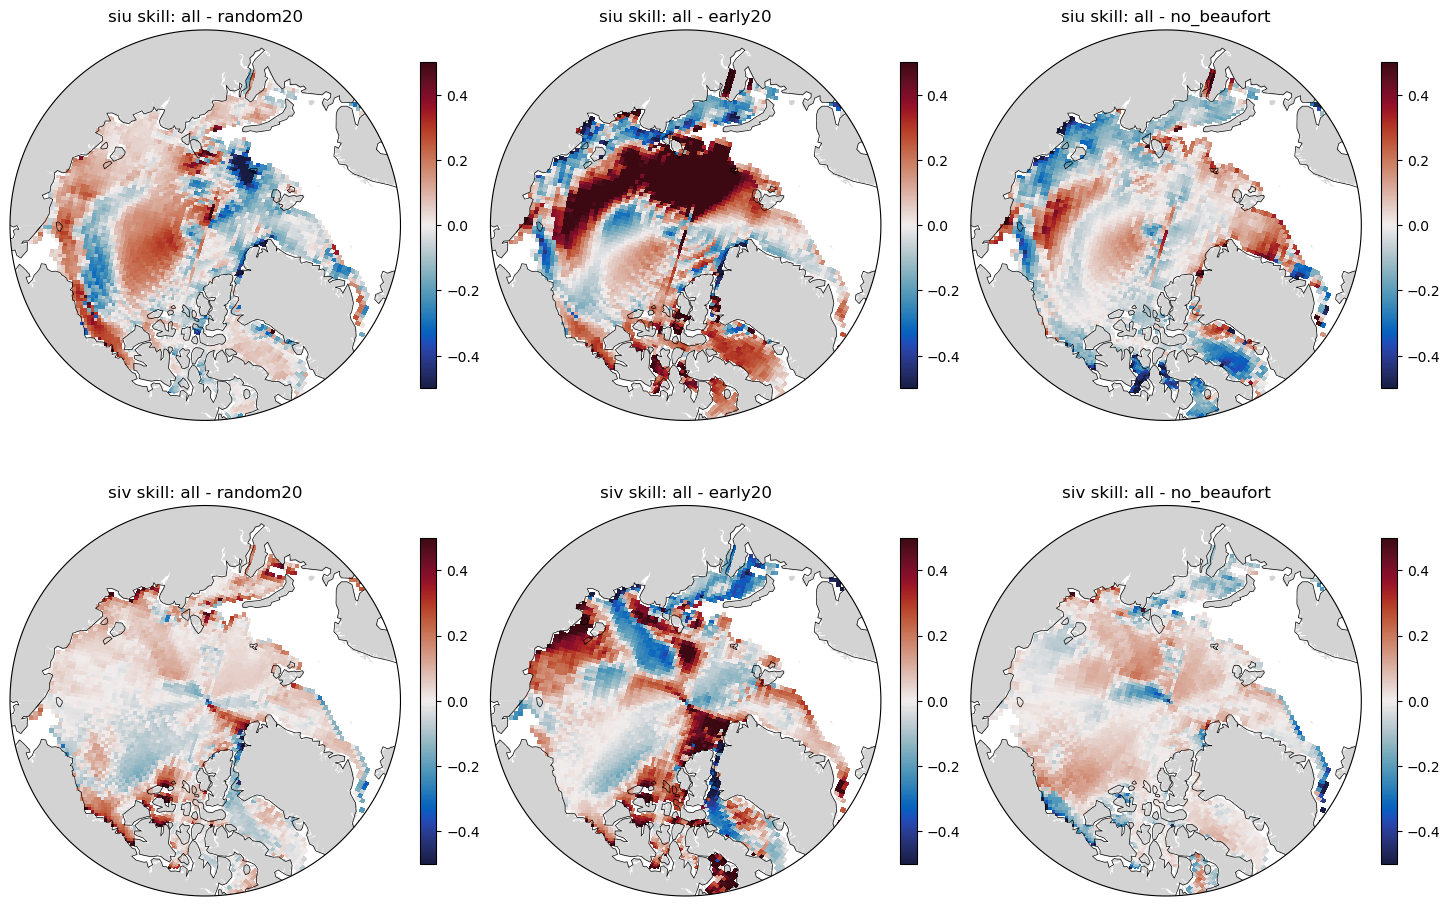

In [23]:
base = results["all"]
others = [r for r in results.values() if r["name"] != "all"]
fig, axs = plt.subplots(2, len(others), figsize=(4.8 * len(others), 9.5), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
for j, r in enumerate(others):
    for k, name in enumerate(TARGETS):
        polar_axes(axs[k, j], f"{name} skill: all - {r['name']}")
        pm = polar_pcolormesh(axs[k, j], lon_map, lat_map, base["skill"][:, :, k] - r["skill"][:, :, k], cmap=cmocean.cm.balance, vmin=-0.5, vmax=0.5)
        plt.colorbar(pm, ax=axs[k, j], shrink=0.7)

/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/3294500996.py:6: RuntimeWarning: Mean of empty slice
  bias = np.where(ice_mask, np.nanmean(r["Y_rec"][:, :, :, k] - Y_true_map[:, :, :, k], axis=2), np.nan)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/3294500996.py:6: RuntimeWarning: Mean of empty slice
  bias = np.where(ice_mask, np.nanmean(r["Y_rec"][:, :, :, k] - Y_true_map[:, :, :, k], axis=2), np.nan)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/3294500996.py:6: RuntimeWarning: Mean of empty slice
  bias = np.where(ice_mask, np.nanmean(r["Y_rec"][:, :, :, k] - Y_true_map[:, :, :, k], axis=2), np.nan)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/3294500996.py:6: RuntimeWarning: Mean of empty slice
  bias = np.where(ice_mask, np.nanmean(r["Y_rec"][:, :, :, k] - Y_true_map[:, :, :, k], axis=2), np.nan)
/var/folders/49/lps4twx568q71258y6kl3wn80000gp/T/ipykernel_79621/3294500996.py:6: RuntimeWarning: Mean of em

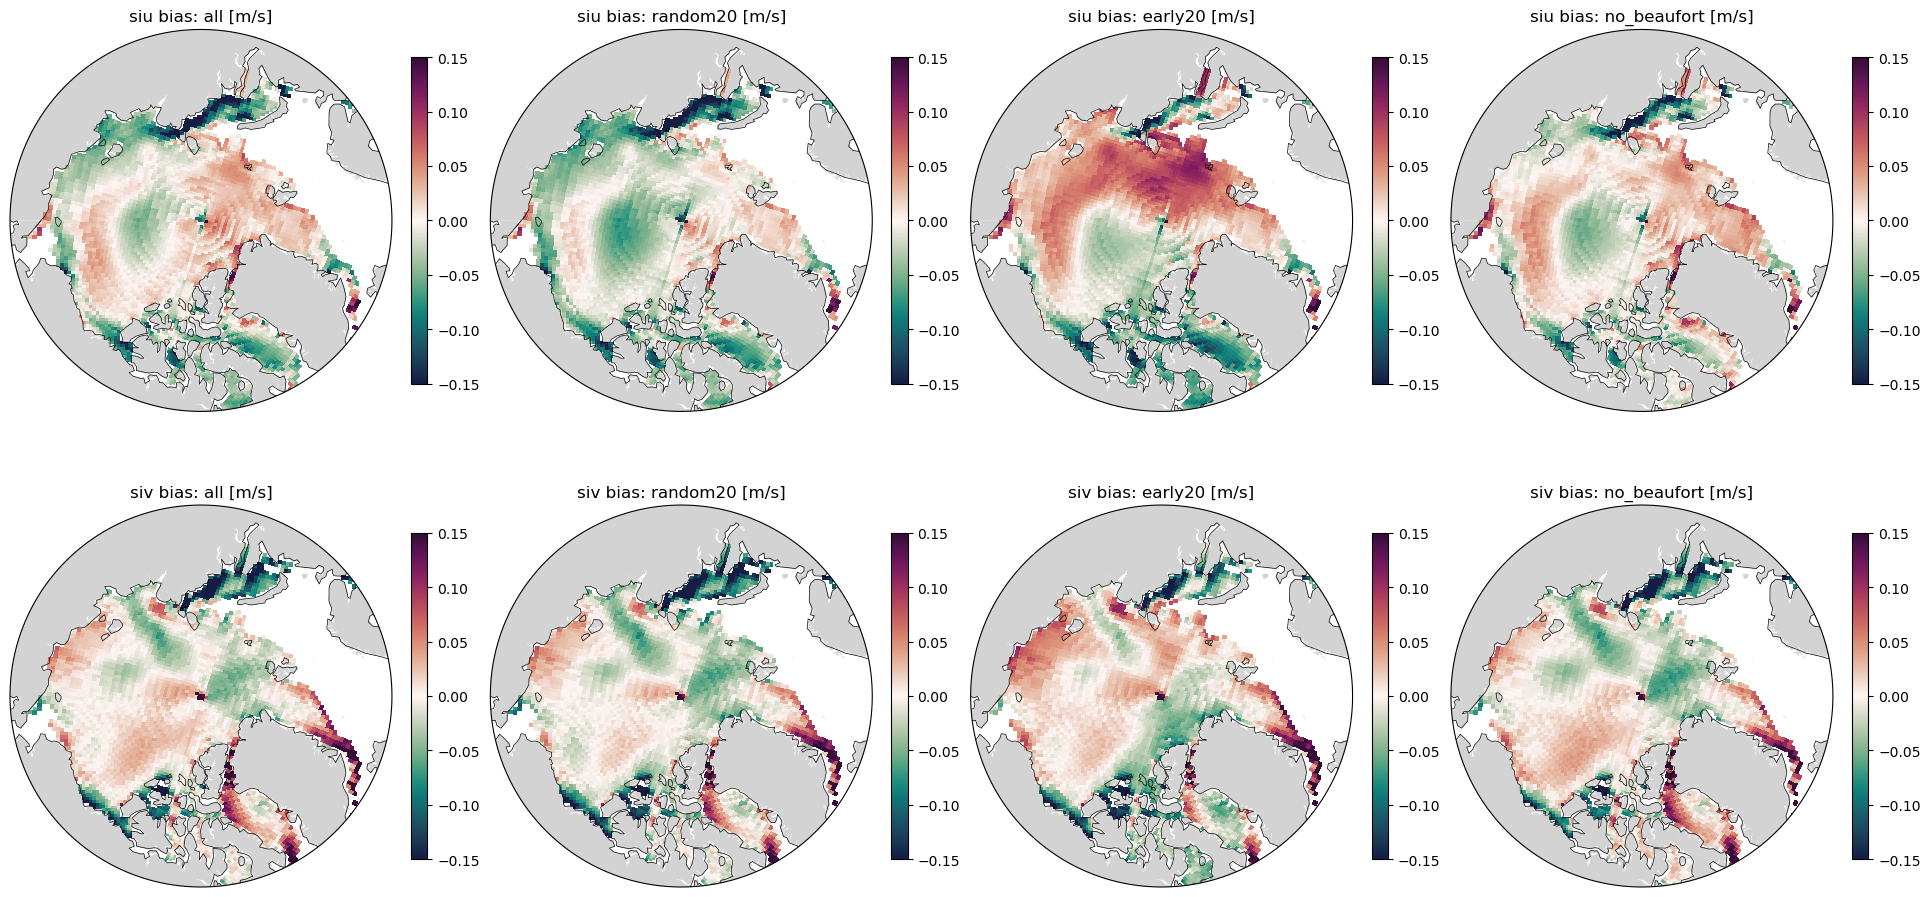

In [24]:
# time-mean bias (reconstruction - truth) of each scenario
fig, axs = plt.subplots(2, len(results), figsize=(4.8 * len(results), 9.5), subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-90)}, layout="constrained")
for j, r in enumerate(results.values()):
    for k, name in enumerate(TARGETS):
        polar_axes(axs[k, j], f"{name} bias: {r['name']} [m/s]")
        bias = np.where(ice_mask, np.nanmean(r["Y_rec"][:, :, :, k] - Y_true_map[:, :, :, k], axis=2), np.nan)
        pm = polar_pcolormesh(axs[k, j], lon_map, lat_map, bias, cmap=cmocean.cm.curl, vmin=-0.15, vmax=0.15)
        plt.colorbar(pm, ax=axs[k, j], shrink=0.7)

In [25]:
# summary table: pooled scores per scenario
print(f"{'scenario':12s} {'n_obs':>7s} {'skill siu':>10s} {'skill siv':>10s} {'r siu':>7s} {'r siv':>7s}")
for r in results.values():
    yt, yp = Y_true_map[ice_mask].reshape(-1, 2), r["Y_rec"][ice_mask].reshape(-1, 2)
    s, c = skill(yt, yp), corr(yt, yp)
    print(f"{r['name']:12s} {r['mask'].sum():7d} {s[0]:10.3f} {s[1]:10.3f} {c[0]:7.3f} {c[1]:7.3f}")

scenario       n_obs  skill siu  skill siv   r siu   r siv
all            11242      0.497      0.600   0.870   0.917
random20        2290      0.484      0.581   0.886   0.912
early20         2248      0.441      0.591   0.831   0.916
no_beaufort     3799      0.537      0.603   0.888   0.919


## 5. Things to try

* **Design your own observing system.** Write a new mask: a single ITP, only summer samples (`doy_obs` between 150 and 250), only north of 85 °N, every 5th day … Which gives the best reconstruction per observation?
* **Fewer members.** Train on 2 members instead of 20. Is the limiting factor the number of ITPs or the number of model realizations?
* **More history.** Add yesterday's wind (or the model's own ice velocity, i.e. persistence) as inputs. Does the network still need `doy`, `lat`, `lon`?
* **Robustness.** Repeat a scenario with `seed=1, 2, 3`. How much of the skill difference between scenarios is just training noise?